### Zadanie dodatkowe 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

In [ ]:
W1 = np.random.normal(loc=0, scale=1, size=1000000)
W2 = np.random.normal(loc=0, scale=1, size=1000000)
rho = 0.5

Z1 = W1
Z2 = rho * W1 + np.sqrt(1- rho**2) * W2

U1 = scipy.stats.norm.cdf(Z1)
U2 = scipy.stats.norm.cdf(Z2)
print(scipy.stats.pearsonr(U1, U2))

PearsonRResult(statistic=np.float64(0.4819129512359916), pvalue=np.float64(0.0))


In [ ]:
def generate_correlated_samples(n, rho, dist1=scipy.stats.norm, dist2=scipy.stats.norm):
    W1 = dist1.rvs(size=n)
    W2 = dist2.rvs(size=n)
    
    Z1 = W1
    Z2 = rho * W1 + np.sqrt(1 - rho**2) * W2
    
    U1 = dist1.cdf(Z1)
    U2 = dist2.cdf(Z2)
    
    return U1, U2

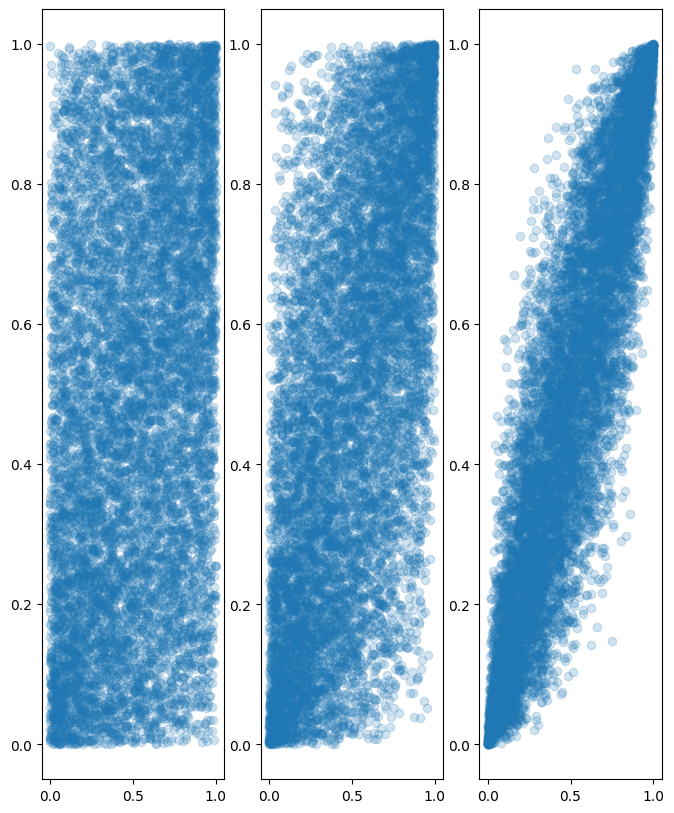

In [ ]:
def plot_cloud_points(rho_set, sample_size, dist1=scipy.stats.norm, dist2=scipy.stats.norm):
    fig, ax = plt.subplots(1, len(rho_set), figsize=(6,8))
    for inx, rho in enumerate(rho_set):
        sample1, sample2 = generate_correlated_samples(sample_size, rho,dist1=dist1, dist2=dist2)
        ax[inx].scatter(sample1, sample2, alpha=0.2)
    plt.show()

plot_cloud_points((0.3, 0.6, 0.9), 10000)
